# Energy Transition & Electric Mobility in Portugal - EDA

**Phase 3: quick first look.** Deeper analysis (seasonality, source volatility,
price correlation, geographic patterns) continues in the next session.

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

PROJECT_ROOT = Path.cwd()
DATA_PROCESSED = PROJECT_ROOT / "data" / "processed"

df_ren = pd.read_csv(DATA_PROCESSED / "ren_daily_production.csv", parse_dates=["date"])
df_eredes = pd.read_csv(
    DATA_PROCESSED / "eredes_mobility_monthly.csv", parse_dates=["date"]
)

print(df_ren.shape, df_eredes.shape)
df_ren[
    ["renovavel_mwh", "nao_renovavel_mwh", "pct_renovavel", "pct_renovavel_com_import"]
].describe()

(1097, 22) (3336, 4)


,renovavel_mwh,nao_renovavel_mwh,pct_renovavel,pct_renovavel_com_import
count,1097.000000,1097.000000,1097.000000,1097.000000
mean,111929.035880,19025.952397,84.997903,67.118140
std,31312.329506,9523.389543,7.506303,13.600079
min,42004.950000,2006.050000,45.600000,28.500000
25%,87920.930000,13116.360000,80.900000,56.500000
50%,106979.590000,18953.880000,84.900000,66.400000
75%,132397.380000,23996.800000,90.100000,77.600000
max,215429.190000,82448.100000,98.700000,98.600000


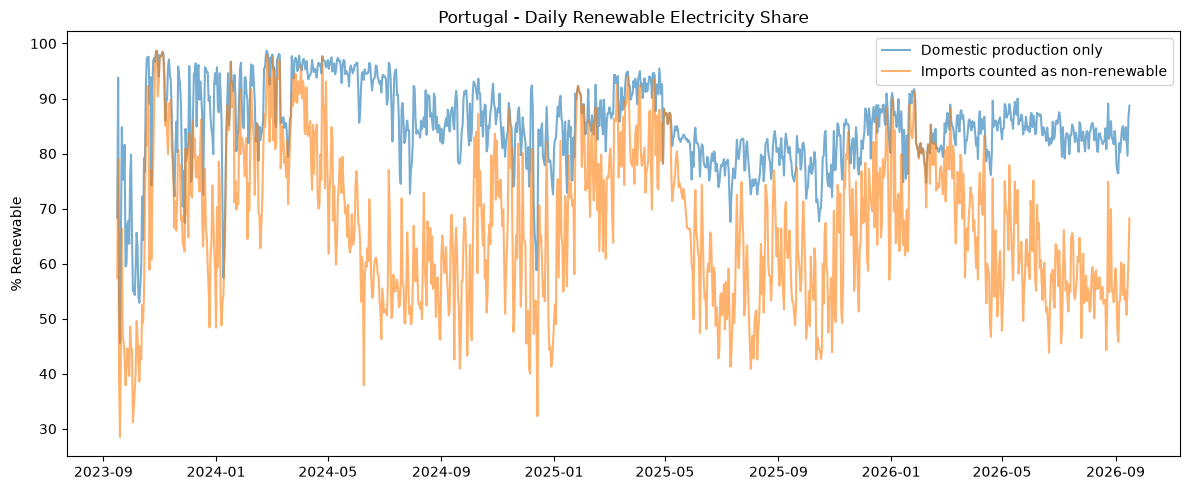

In [6]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(
    df_ren["date"], df_ren["pct_renovavel"], label="Domestic production only", alpha=0.6
)
ax.plot(
    df_ren["date"],
    df_ren["pct_renovavel_com_import"],
    label="Imports counted as non-renewable",
    alpha=0.6,
)
ax.set_ylabel("% Renewable")
ax.set_title("Portugal - Daily Renewable Electricity Share")
ax.legend()
plt.tight_layout()
plt.show()

## Smoothed renewable share chart

Daily values are noisy - applying a rolling average and adding light
year-boundary lines to make the trend and yearly comparison easier to read.
Testing both a 3-day and a 7-day (weekly) window to see which reads better.

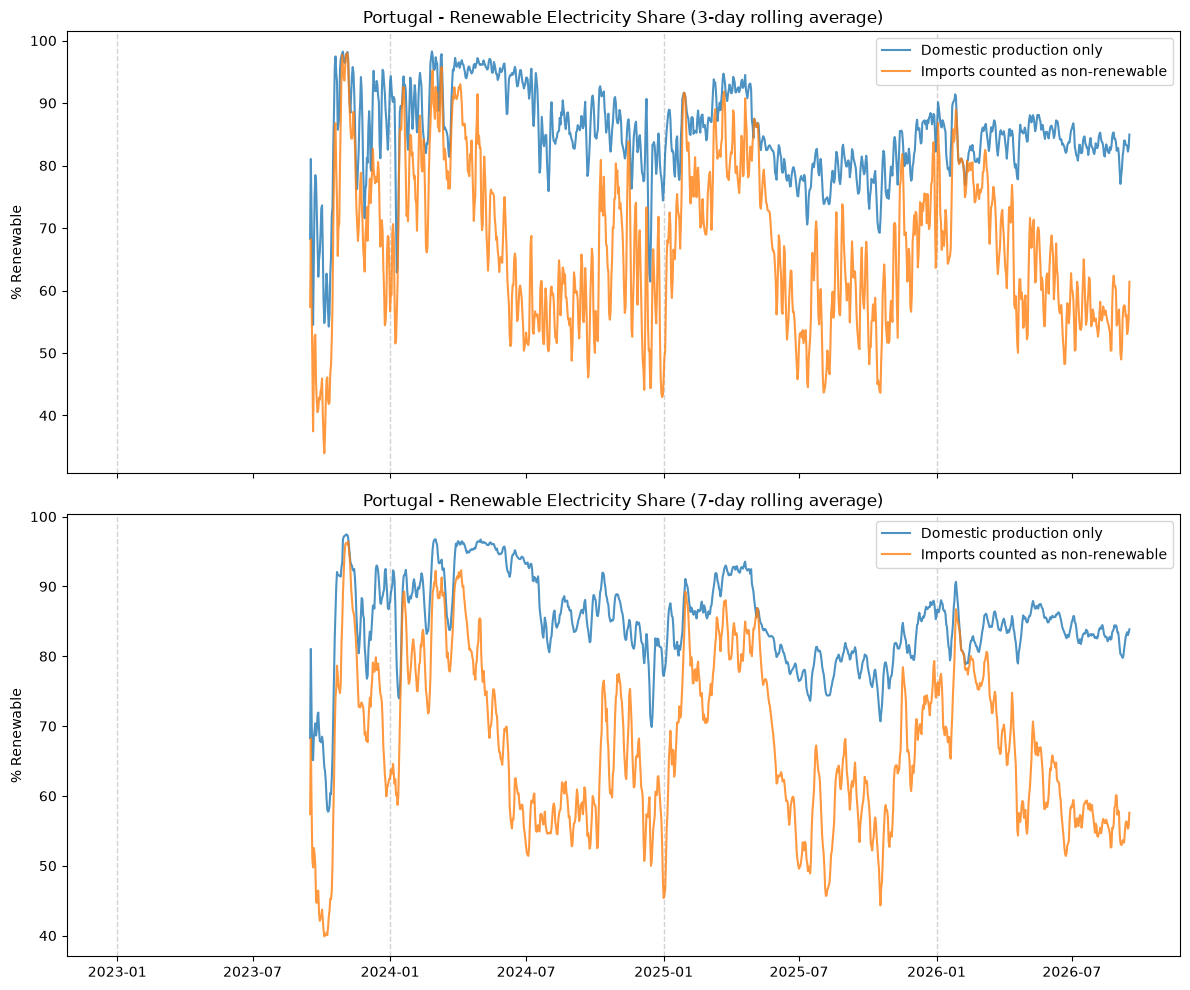

In [ ]:
def plot_renewable_share(df, window_days, ax=None):
    # Time-based rolling window (not row-based) — correctly handles the
    # 2 missing days in the data without shifting the average
    df_indexed = df.set_index("date").sort_index()
    smoothed = (
        df_indexed[["pct_renovavel", "pct_renovavel_com_import"]]
        .rolling(f"{window_days}D")
        .mean()
    )

    if ax is None:
        fig, ax = plt.subplots(figsize=(12, 5))

    ax.plot(
        smoothed.index,
        smoothed["pct_renovavel"],
        label="Domestic production only",
        alpha=0.8,
    )
    ax.plot(
        smoothed.index,
        smoothed["pct_renovavel_com_import"],
        label="Imports counted as non-renewable",
        alpha=0.8,
    )

    # Light vertical line at the start of each year present in the data
    for year in range(df["date"].dt.year.min(), df["date"].dt.year.max() + 1):
        ax.axvline(
            pd.Timestamp(f"{year}-01-01"),
            color="lightgray",
            linestyle="--",
            linewidth=1,
            zorder=0,
        )

    ax.set_ylabel("% Renewable")
    ax.set_title(
        f"Portugal - Renewable Electricity Share ({window_days}-day rolling average)"
    )
    ax.legend()
    return ax


fig, axes = plt.subplots(2, 1, figsize=(12, 10), sharex=True)
plot_renewable_share(df_ren, window_days=3, ax=axes[0])
plot_renewable_share(df_ren, window_days=7, ax=axes[1])
plt.tight_layout()
plt.show()